对于LC数据集我们提出以下四个问题：

1.用户画像，包含使用平台贷款业务的用户的性别比例，学历水平，是否为旧有用户，年龄分布等信息。

2.资金储备，每日借款金额大概多少？波动有多大？从而公司每日需准备多少资金可以保证不会出现资金短缺？

3.用户逾期率，借款人的初始评级、借款类型、性别、年龄等特征对于逾期还款的概率有无显著影响？哪些群体逾期还款率明显较高？

4.借款利率，哪些群体更愿意接受较高的借款利率？

# 获取数据

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [112]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

In [2]:
LC=pd.read_csv('LC.csv')

# 数据清洗

In [4]:
LC.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 328553 entries, 0 to 328552
Data columns (total 21 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   ListingId  328553 non-null  int64  
 1   借款金额       328553 non-null  int64  
 2   借款期限       328553 non-null  int64  
 3   借款利率       328553 non-null  float64
 4   借款成功日期     328553 non-null  object 
 5   初始评级       328553 non-null  object 
 6   借款类型       328553 non-null  object 
 7   是否首标       328553 non-null  object 
 8   年龄         328553 non-null  int64  
 9   性别         328553 non-null  object 
 10  手机认证       328553 non-null  object 
 11  户口认证       328553 non-null  object 
 12  视频认证       328553 non-null  object 
 13  学历认证       328553 non-null  object 
 14  征信认证       328553 non-null  object 
 15  淘宝认证       328553 non-null  object 
 16  历史成功借款次数   328553 non-null  int64  
 17  历史成功借款金额   328553 non-null  float64
 18  总待还本金      328553 non-null  float64
 19  历史正常还款期数   328553 non-n

In [5]:
# 发现“借款成功日期”类型不为时间类型
LC['借款成功日期']=pd.to_datetime(LC['借款成功日期'])

In [8]:
LC.describe().T

,count,mean,min,25%,50%,75%,max,std
ListingId,328553.0,19079479.261072,126541.0,11908871.0,19523251.0,26298621.0,32819531.0,8375769.043234
借款金额,328553.0,4423.816906,100.0,2033.0,3397.0,5230.0,500000.0,11219.664024
借款期限,328553.0,10.213594,1.0,6.0,12.0,12.0,24.0,2.780444
借款利率,328553.0,20.601439,6.5,20.0,20.0,22.0,24.0,1.772408
借款成功日期,328553,2016-08-05 22:21:24.987201280,2015-01-01 00:00:00,2016-05-08 00:00:00,2016-09-11 00:00:00,2016-12-01 00:00:00,2017-01-30 00:00:00,NaN
年龄,328553.0,29.143042,17.0,24.0,28.0,33.0,56.0,6.624286
历史成功借款次数,328553.0,2.323159,0.0,0.0,2.0,3.0,649.0,2.922361
历史成功借款金额,328553.0,8785.856771,0.0,0.0,5000.0,10355.0,7405926.0,35027.363482
总待还本金,328553.0,3721.665361,0.0,0.0,2542.41,5446.81,1172652.87,8626.061205
历史正常还款期数,328553.0,9.947658,0.0,0.0,5.0,13.0,2507.0,14.839899


1.从年龄分布来看，借款年龄最小为17岁，最大为56岁，且33岁以下借款人占75%，说明中青年人较多
2.从借款金额来看，借款金额最小为100元，最大为50万元，且5230元以下借款金额占75%，说明小额贷款较多

# 分析

## 1.用户画像，包含使用平台贷款业务的用户的性别比例，学历水平，是否为旧有用户，年龄分布等信息。

In [9]:
plt.rcParams['font.sans-serif']=['Microsoft YaHei']
plt.rcParams['font.serif']=['Microsoft YaHei']

### 性别分析

In [14]:
# 男女比例占比
LC['性别'].value_counts()/LC['性别'].value_counts().sum()

性别
男    0.675526
女    0.324474
Name: count, dtype: float64

<Axes: ylabel='count'>

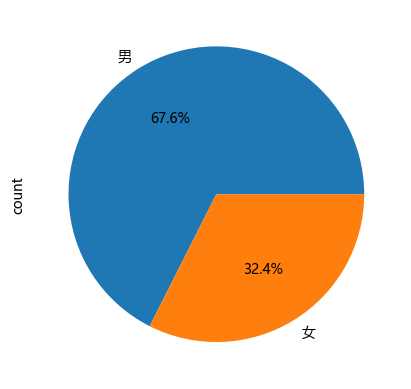

In [24]:
LC['性别'].value_counts().plot(kind='pie',autopct='%.1f%%')

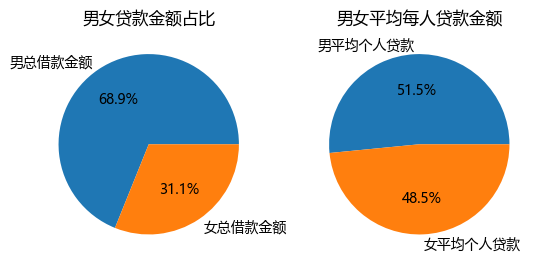

In [34]:
# 男女贷款金额占比
plt.subplot(121)
male_je=LC.loc[LC['性别']=='男','借款金额']
female_je=LC.loc[LC['性别']!='男','借款金额']
data=[male_je.sum(),female_je.sum()]
_=plt.pie(data,labels=['男总借款金额','女总借款金额'],autopct='%.1f%%',)
_=plt.title('男女贷款金额占比')

# 男女平均每人贷款金额
plt.subplot(122)
data=[male_je.mean(),female_je.mean()]
_=plt.pie(data,labels=['男平均个人贷款','女平均个人贷款'],autopct='%.1f%%')
_=plt.title('男女平均每人贷款金额')

1. 可以看出男性在平台人数占比67.6%
2. 男性在平台借款总金额达到68.9%，但从平均个人贷款方面看，男性（51.5%）只比女性（48.5%）多一点，可以看出男女贷款金额需求差别不大

### 新老客户

In [35]:
LC.columns

Index(['ListingId', '借款金额', '借款期限', '借款利率', '借款成功日期', '初始评级', '借款类型', '是否首标',
       '年龄', '性别', '手机认证', '户口认证', '视频认证', '学历认证', '征信认证', '淘宝认证', '历史成功借款次数',
       '历史成功借款金额', '总待还本金', '历史正常还款期数', '历史逾期还款期数'],
      dtype='object')

In [37]:
LC.groupby('是否首标')['借款金额'].sum()

是否首标
否    956102749
是    497355567
Name: 借款金额, dtype: int64

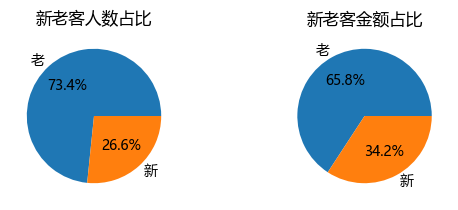

In [50]:
# 新老客人数占比
plt.subplot(221)
data=LC.groupby('是否首标')['ListingId'].count()
_=plt.pie(data,labels=['老','新'],autopct='%.1f%%')
_=plt.title('新老客人数占比')
# 新老客金额占比
plt.subplot(222)
new=LC.loc[LC['是否首标']=='否','借款金额']
old=LC.loc[LC['是否首标']!='否','借款金额']
data=[new.sum(),old.sum()]
_=plt.pie(data,labels=['老','新'],autopct='%.1f%%')
_=plt.title('新老客金额占比')

In [51]:
(LC.groupby('是否首标')['借款金额'].sum())/LC.groupby('是否首标')['ListingId'].count()

是否首标
否    3965.750338
是    5686.468187
dtype: float64

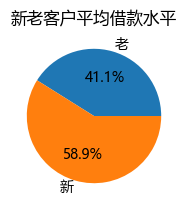

In [52]:
# 新老客户平均借款水平
plt.subplot(223)
data=(LC.groupby('是否首标')['借款金额'].sum())/LC.groupby('是否首标')['ListingId'].count()
_=plt.pie(data,labels=['老','新'],autopct='%.1f%%')
_=plt.title('新老客户平均借款水平')

1. 老客户占比高达73.4%，说明平台粘性比较高
2. 且新客平均借款金额（58.9%）比老客户（41.1%）高，（将近1700元差额）

Text(0.5, 1.0, '女性中新老客户金额占比')

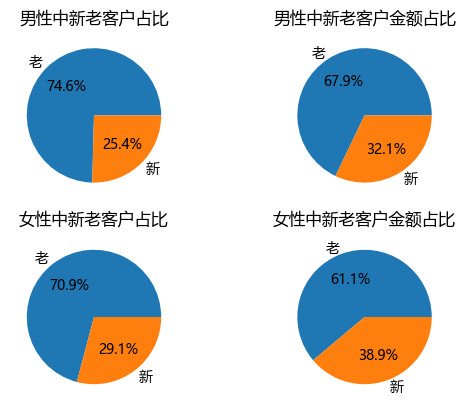

In [59]:
# 男女视角下，新老客占比及金额
plt.subplot(221)
data=LC.loc[LC['性别']=='男',:].groupby('是否首标')['ListingId'].count()
_=plt.pie(data,labels=['老','新'],autopct='%.1f%%')
plt.title('男性中新老客户占比')

plt.subplot(222)
data=LC.loc[LC['性别']=='男',:].groupby('是否首标')['借款金额'].sum()
_=plt.pie(data,labels=['老','新'],autopct='%.1f%%')
plt.title('男性中新老客户金额占比')

plt.subplot(223)
data=LC.loc[LC['性别']=='女',:].groupby('是否首标')['ListingId'].count()
_=plt.pie(data,labels=['老','新'],autopct='%.1f%%')
plt.title('女性中新老客户占比')

plt.subplot(224)
data=LC.loc[LC['性别']=='女',:].groupby('是否首标')['借款金额'].sum()
_=plt.pie(data,labels=['老','新'],autopct='%.1f%%')
plt.title('女性中新老客户金额占比')


In [60]:
new=LC.loc[LC['是否首标']=='否',:]
old=LC.loc[LC['是否首标']!='否',:]

Text(0.5, 1.0, '新客中男女金额占比')

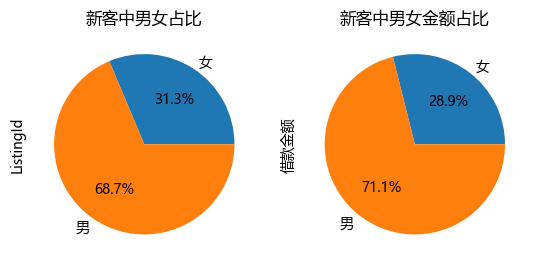

In [74]:
# 新客视角下，男女占比及金额占比
plt.subplot(121)
new.groupby('性别')['ListingId'].count().plot(kind='pie',autopct='%.1f%%')
plt.title('新客中男女占比')

plt.subplot(122)
new.groupby('性别')['借款金额'].sum().plot(kind='pie',autopct='%.1f%%')
plt.title('新客中男女金额占比')


1. 发现更多的新客为男生，但在新客视角下去看性别，发现性别对新客影响不大

### 年龄

In [78]:
LC.describe()['年龄']

count    328553.000000
mean         29.143042
min          17.000000
25%          24.000000
50%          28.000000
75%          33.000000
max          56.000000
std           6.624286
Name: 年龄, dtype: float64

In [91]:
bins=[15,20,25,30,35,40,60]

<Axes: xlabel='年龄'>

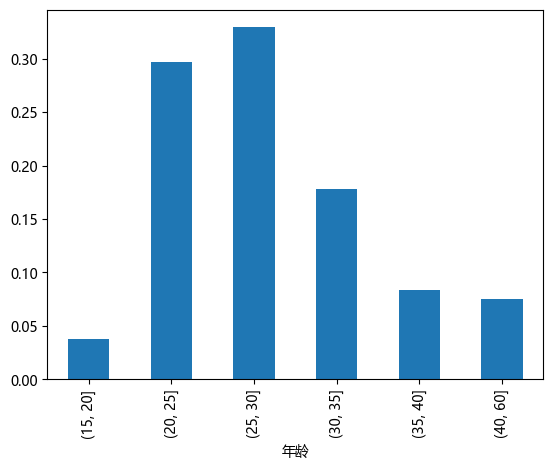

In [93]:
(pd.cut(LC['年龄'],bins=bins).value_counts()/pd.cut(LC['年龄'],bins=bins).value_counts().sum()).sort_index().plot(kind='bar')

1. 20-30年龄段的居多，是重点

In [94]:
LC['年龄区间']=pd.cut(LC['年龄'],bins=bins)

C:\Users\lenovo\AppData\Local\Temp\ipykernel_42832\2585153853.py:2: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  LC.pivot_table(index='年龄区间',columns='是否首标',values='借款金额',aggfunc=np.size).plot()


<Axes: xlabel='年龄区间'>

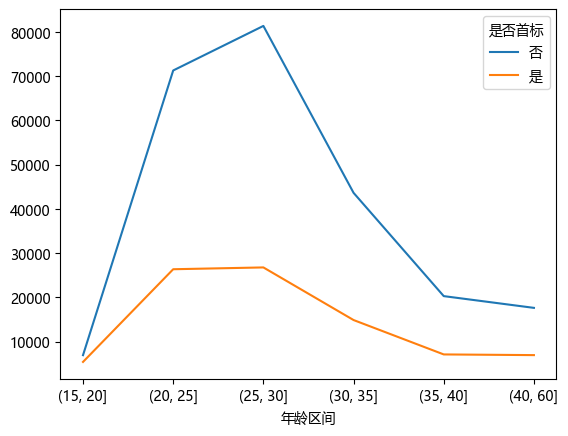

In [99]:
# 年龄区间下新老客借款记录数，老：否  新：是
LC.pivot_table(index='年龄区间',columns='是否首标',values='借款金额',aggfunc=np.size).plot()

In [130]:
# 新老客
new=LC.loc[LC['是否首标']=='是',:]
old=LC.loc[LC['是否首标']=='否',:]

年龄区间
(15, 20]    0.070460
(20, 25]    0.142758
(25, 30]    0.184277
(30, 35]    0.201043
(35, 40]    0.202872
(40, 60]    0.198590
dtype: float64

年龄区间
(15, 20]    0.044756
(20, 25]    0.130040
(25, 30]    0.175640
(30, 35]    0.204706
(35, 40]    0.224122
(40, 60]    0.220737
dtype: float64

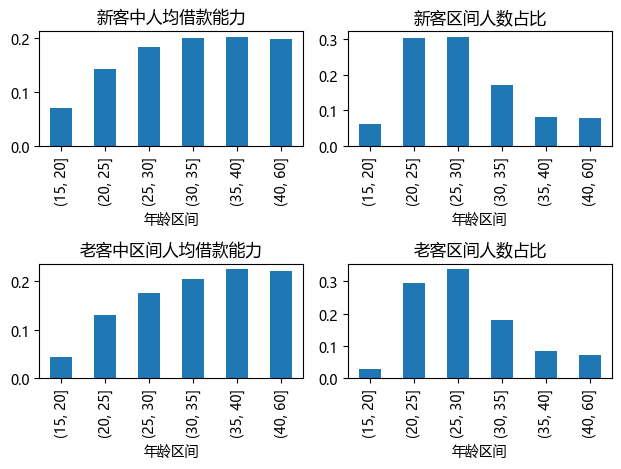

In [142]:
# 新客中年龄区间对应的平均借款力占比，（区间总金额/区间总人数）/（区间总金额/区间总人数）.sum()
plt.subplot(221)
data=(new.groupby('年龄区间')['借款金额'].sum()/new.groupby('年龄区间')['ListingId'].count())/(new.groupby('年龄区间')['借款金额'].sum()/new.groupby('年龄区间')['ListingId'].count()).sum()
display(data)
data.plot(kind='bar',title='新客中人均借款能力')
# 新客人数占比
plt.subplot(222)
(new.groupby('年龄区间')['ListingId'].count()/new.groupby('年龄区间')['ListingId'].count().sum()).plot(kind='bar',title='新客区间人数占比')

# 老客中年龄区间对应的平均借款力占比，（区间总金额/区间总人数）/（区间总金额/区间总人数）.sum()
plt.subplot(223)
data=(old.groupby('年龄区间')['借款金额'].sum()/old.groupby('年龄区间')['ListingId'].count())/(old.groupby('年龄区间')['借款金额'].sum()/old.groupby('年龄区间')['ListingId'].count()).sum()
display(data)
data.plot(kind='bar',title='老客中区间人均借款能力')
# 新客人数占比
plt.subplot(224)
(old.groupby('年龄区间')['ListingId'].count()/old.groupby('年龄区间')['ListingId'].count().sum()).plot(kind='bar',title='老客区间人数占比')


plt.tight_layout()

1. 结合前面新客的平均借款能力为5686，比老客高，所以在年龄区间上，15-30的新客更有潜力，因为平均借贷能力比老客高

## 2.资金储备，每日借款金额大概多少？波动有多大？从而公司每日需准备多少资金可以保证不会出现资金短缺？

In [146]:
save_money=LC[['借款成功日期','借款金额']].copy()

<Axes: xlabel='借款成功日期'>

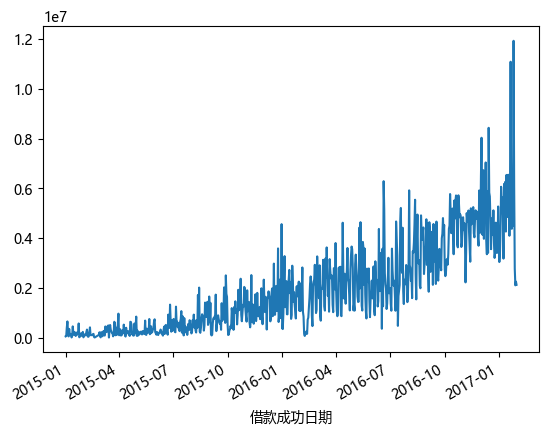

In [148]:
save_money.groupby('借款成功日期')['借款金额'].sum().plot()

<Axes: xlabel='借款成功日期'>

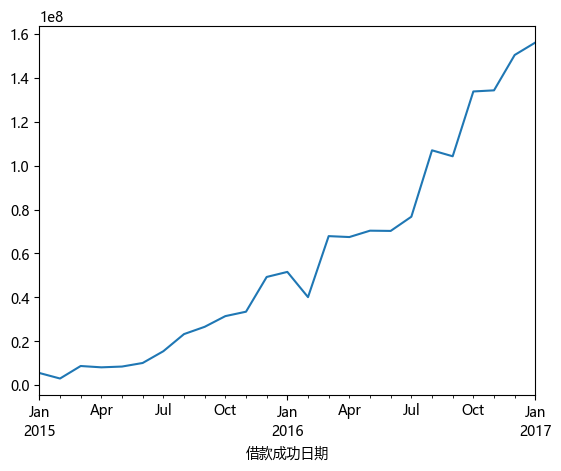

In [151]:
save_money.set_index('借款成功日期').resample('M')['借款金额'].sum().plot()

有两种处理方式：1.统计学的角度(3西格玛原则)    2.算法-回归

In [159]:
# 2017-01每一天的汇总借款金额
temp=save_money.set_index('借款成功日期').loc['2017-01'].reset_index().groupby('借款成功日期')['借款金额'].sum()

In [161]:
temp.sum(),temp.max()

(np.int64(156139914), np.int64(11938937))

In [162]:
temp.mean()-3*temp.std(),temp.mean()+3*temp.std()

(np.float64(-1405518.6307427278), np.float64(11814846.230742726))

 故每日可准备现金1181,4846元，约119万元

## 3.用户逾期率，借款人的初始评级、借款类型、性别、年龄等特征对于逾期还款的概率有无显著影响？哪些群体逾期还款率明显较高？

### 逾期率 = 历史逾期次数/总次数

In [144]:
LC.columns

Index(['ListingId', '借款金额', '借款期限', '借款利率', '借款成功日期', '初始评级', '借款类型', '是否首标',
       '年龄', '性别', '手机认证', '户口认证', '视频认证', '学历认证', '征信认证', '淘宝认证', '历史成功借款次数',
       '历史成功借款金额', '总待还本金', '历史正常还款期数', '历史逾期还款期数', '年龄区间'],
      dtype='object')

In [165]:
overdue=LC[['借款金额','初始评级','借款类型','性别','年龄','历史正常还款期数','历史逾期还款期数']]

In [167]:
overdue['逾期率']=overdue['历史逾期还款期数']/(overdue['历史逾期还款期数']+overdue['历史正常还款期数'])

C:\Users\lenovo\AppData\Local\Temp\ipykernel_42832\1653440107.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  overdue['逾期率']=overdue['历史逾期还款期数']/(overdue['历史逾期还款期数']+overdue['历史正常还款期数'])


In [169]:
overdue.head(5)

,借款金额,初始评级,借款类型,性别,年龄,历史正常还款期数,历史逾期还款期数,逾期率
0,18000,C,其他,男,35,57,16,0.219178
1,9453,D,其他,男,34,13,1,0.071429
2,27000,E,普通,男,41,25,3,0.107143
3,25000,C,其他,男,34,41,1,0.023810
4,20000,C,电商,男,24,118,14,0.106061


In [174]:
overdue['初始评级'].value_counts().sort_index()

初始评级
A     10284
B     33188
C    131705
D    134860
E     17027
F      1489
Name: count, dtype: int64

<Axes: xlabel='初始评级'>

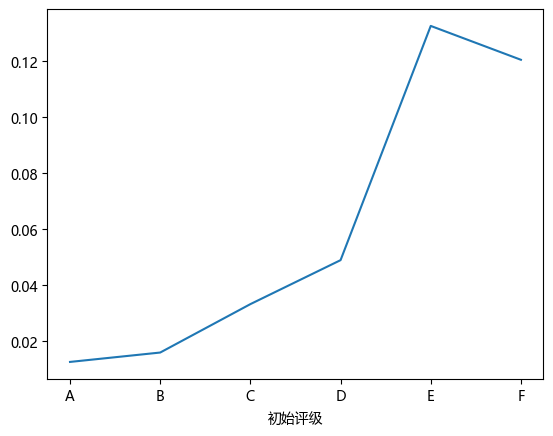

In [173]:
overdue.groupby('初始评级')['逾期率'].mean().plot()

1. 初始评级对于借款能力能有个有效的预测
2. EF的表现可能是由于数据量级太少导致，EF的逾期率呈现断崖式上升

### 借款类型

In [175]:
overdue.head(2)

,借款金额,初始评级,借款类型,性别,年龄,历史正常还款期数,历史逾期还款期数,逾期率
0,18000,C,其他,男,35,57,16,0.219178
1,9453,D,其他,男,34,13,1,0.071429


In [176]:
overdue['借款类型'].unique()

array(['其他', '普通', '电商', 'APP闪电'], dtype=object)

<Axes: xlabel='借款类型'>

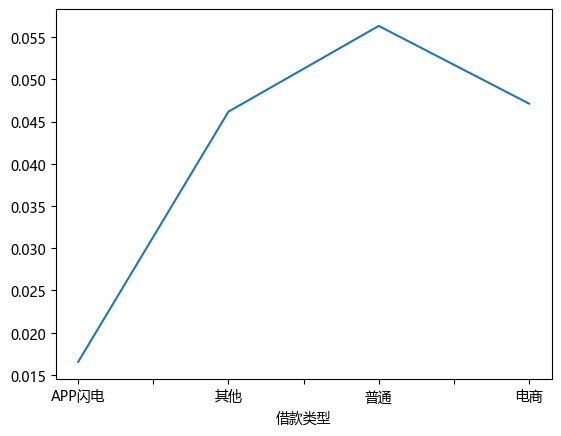

In [178]:
overdue.groupby('借款类型')['逾期率'].mean().plot()

1. 可以看出app闪电类型的借款逾期率最低，公司可以加强与app闪电的合作

### 性别

In [184]:
overdue.groupby('性别')['借款类型'].count()

性别
女    106607
男    221946
Name: 借款类型, dtype: int64

<Axes: xlabel='性别'>

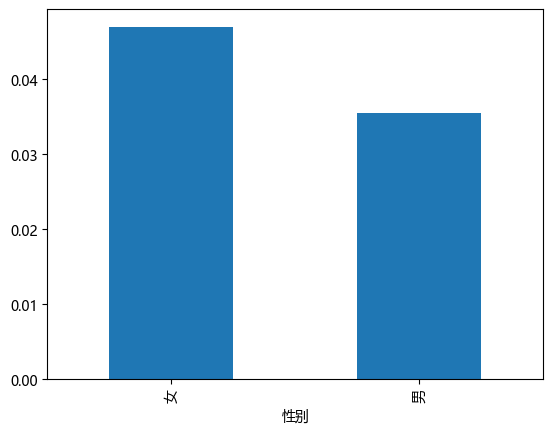

In [180]:
overdue.groupby('性别')['逾期率'].mean().plot(kind='bar')

### 借款区间

In [182]:
overdue.describe().T

,count,mean,std,min,25%,50%,75%,max
借款金额,328553.0,4423.816906,11219.664024,100.0,2033.0,3397.0,5230.0,500000.0
年龄,328553.0,29.143042,6.624286,17.0,24.0,28.0,33.0,56.0
历史正常还款期数,328553.0,9.947658,14.839899,0.0,0.0,5.0,13.0,2507.0
历史逾期还款期数,328553.0,0.423250,1.595681,0.0,0.0,0.0,0.0,60.0
逾期率,239602.0,0.039078,0.108068,0.0,0.0,0.0,0.0,1.0


C:\Users\lenovo\AppData\Local\Temp\ipykernel_42832\1610133745.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  overdue['借款区间']=pd.cut(overdue['借款金额'],bins=bins)


<Axes: xlabel='借款区间'>

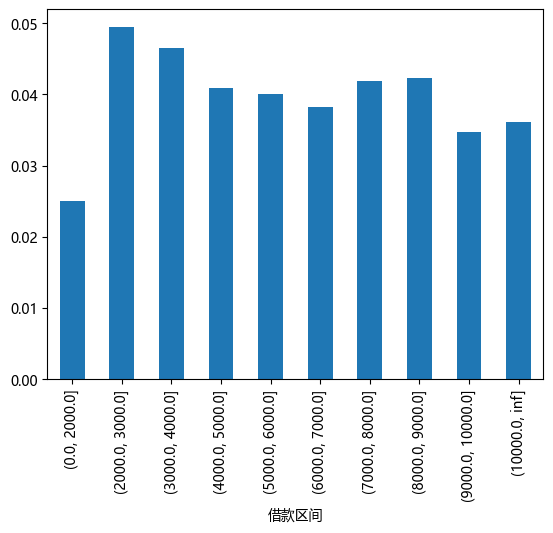

In [191]:
bins=[0,2000,3000,4000,5000,6000,7000,8000,9000,10000,np.inf]
overdue['借款区间']=pd.cut(overdue['借款金额'],bins=bins)
overdue.groupby('借款区间')['逾期率'].mean().plot(kind="bar")

1. 借款金额在2000元以下的逾期率最低，2000-4000元的逾期率较高，可以考虑促进小额贷款的营销模式

# 4.借款利率，哪些群体更愿意接受较高的借款利率？

In [193]:
LC.head(2)

,ListingId,借款金额,借款期限,借款利率,借款成功日期,初始评级,借款类型,是否首标,年龄,性别,...,视频认证,学历认证,征信认证,淘宝认证,历史成功借款次数,历史成功借款金额,总待还本金,历史正常还款期数,历史逾期还款期数,年龄区间
0,126541,18000,12,18.0,2015-05-04,C,其他,否,35,男,...,成功认证,未成功认证,未成功认证,未成功认证,11,40326.0,8712.73,57,16,"(30, 35]"
1,133291,9453,12,20.0,2015-03-16,D,其他,否,34,男,...,未成功认证,未成功认证,未成功认证,未成功认证,4,14500.0,7890.64,13,1,"(30, 35]"


In [198]:
np.sort(LC['借款利率'].unique())

array([ 6.5 ,  8.  ,  8.5 ,  9.  , 10.  , 10.5 , 11.  , 12.  , 13.  ,
       14.  , 14.4 , 14.6 , 15.  , 15.1 , 15.8 , 16.  , 17.  , 18.  ,
       18.2 , 18.3 , 19.  , 20.  , 20.2 , 20.5 , 21.  , 21.4 , 22.  ,
       22.2 , 22.24, 22.3 , 22.4 , 22.5 , 22.88, 23.  , 24.  ])

In [199]:
LC['借款利率'].describe()

count    328553.000000
mean         20.601439
std           1.772408
min           6.500000
25%          20.000000
50%          20.000000
75%          22.000000
max          24.000000
Name: 借款利率, dtype: float64

In [201]:
LC.groupby('借款利率')['借款金额'].count().sort_index()

借款利率
6.50          1
8.00          1
8.50          1
9.00         12
10.00         9
10.50         1
11.00         7
12.00       589
13.00        48
14.00       622
14.40         1
14.60         1
15.00       201
15.10         6
15.80         2
16.00     10558
17.00        36
18.00     38777
18.20         1
18.30         1
19.00        60
20.00    126330
20.20         1
20.50         2
21.00       149
21.40         1
22.00    137899
22.20         2
22.24         1
22.30         1
22.40         6
22.50         1
22.88         1
23.00      1147
24.00     12077
Name: 借款金额, dtype: int64

In [208]:
# 可由业务角度出发，选定高低借款利率的分界值，这里选用20作为分界值
LC["借款利率评级"]=LC['借款利率'].apply(lambda x:'较高' if x>20 else '较低')

In [209]:
LC.groupby(['借款利率评级','性别'])['借款金额'].count().unstack()/(LC.groupby(['借款利率评级','性别'])['借款金额'].count().unstack().sum())

性别,女,男
借款利率评级,,
较低,0.616385,0.502618
较高,0.383615,0.497382


1. 可看出女性中能接受低利率的比较多，而且女性逾期率大于男性，所以我们可以针对女性定制化产品，比如 分笔贷款，降低d